---

# Tugas Besar 2 IF3170 Inteligensi Artifisial


---

## Group 12

- Muhammad Ashkar (13524007)
- Tengku Naufal Saqib (13524012)
- Rhenaldy Cahyadi Putra (13524039)
- Fayyaz Akmal Lauda (13524076)
- Muhammad Faiz Alfada Dharma (13524097)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pembatalan pemesanan membuat kamar kosong yang seharusnya bisa terjual ke tamu lain. Memprediksi pembatalan sejak dini membantu penginapan merencanakan overbooking, mengirim pengingat, dan menyusun kebijakan pembatalan yang tepat.

## Aim

Membangun model klasifikasi biner yang memprediksi apakah suatu pemesanan dibatalkan (is_canceled = 1) atau tidak (0). Kelima algoritma (KNN, DTL, Logistic Regression, SVM, Naive Bayes) diimplementasikan from scratch, lalu dibandingkan dengan scikit-learn.

## Metric

*To be written by the group.*

## Dataset

*To be written by the group.*

## Approach

*To be written by the group.*

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [49]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Import Libraries

Every import of the notebook is kept in this cell.

In [50]:
import os
import sys
import random
from pathlib import Path

import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder, KBinsDiscretizer
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

root = (Path.cwd()if (Path.cwd() / "src").exists()else Path.cwd().parent)
sys.path.insert(0, str(root))

from src.algorithms.knn import KNN
from src.algorithms.naive_bayes import NaiveBayes

## Settings

Paths and shared constants are kept in this class.

In [51]:
class Settings:
    SEED = 42

    # Kernel dapat berjalan dari root proyek atau folder src.
    PROJECT_DIR = Path.cwd()
    if not (PROJECT_DIR / 'data').exists():
        PROJECT_DIR = PROJECT_DIR.parent

    DATA_DIR = PROJECT_DIR / 'data'
    OUTPUT_DIR = PROJECT_DIR / 'output'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [52]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [53]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [54]:
train_df = train_df.drop(columns="id")
test_df = test_df.drop(columns="id")

# ==========================================
# Describe Data
# ==========================================

print("=====================")
print("Train Dataset")
print("=====================")
print(f"Train Dataset: {train_df.shape}")
display(train_df.describe())

print("\n=====================")
print("Test Dataset")
print("=====================")
print(f"Test Dataset: {test_df.shape}")
display(test_df.describe())


Train Dataset
Train Dataset: (27373, 18)


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000



Test Dataset
Test Dataset: (6844, 17)


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
count,6664.000000,6097.000000,6844.000000,6844.000000,6597.000000,6554.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6.304000e+03,6251.000000
mean,1.844088,0.119567,0.796610,2.205435,0.033500,85.365426,2023.818235,7.401812,15.702659,0.027323,0.031414,0.181911,1.714169e+06,0.670613
std,0.519615,0.422822,0.858793,1.379860,0.179952,85.989244,0.385679,3.050240,8.681514,0.163035,0.444205,1.917124,5.712354e+05,0.792443
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.340000e+06,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,57.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.643000e+06,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,125.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.010250e+06,1.000000
max,4.000000,3.000000,6.000000,17.000000,1.000000,443.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,53.000000,5.700000e+06,5.000000


In [55]:
# ==========================================
# Data Types
# ==========================================
display(train_df.dtypes.to_frame(name="dtype"))

,dtype
num_adults,float64
num_children,float64
weekend_nights,int64
weekday_nights,int64
meal_package,str
needs_parking,float64
room_category,str
days_before_arrival,float64
arrival_year,int64
arrival_month,int64


## Explore Data

This part covers distributions and relationships between attributes.

In [56]:
# ==========================================
# EXPLORE DATA
# ==========================================

# Identify all the columns
# Numerical Columns
numerical_cols = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests",
    "arrival_year",
    "arrival_month",
    "arrival_day"
]

# Categorical Columns
categorical_cols = [
    "meal_package",
    "needs_parking",
    "room_category",
    "booking_channel",
    "is_returning_guest"
]

# Target Columns
target_cols = [
    "is_canceled"
]


Distribusi Data Target



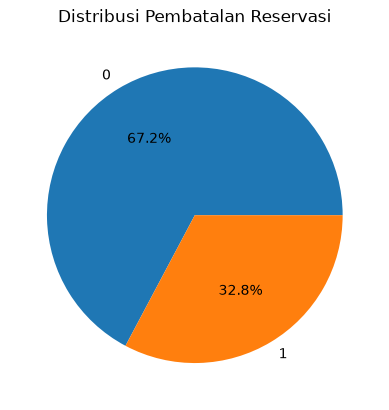

In [57]:
# ==========================================
# DISTRIBUSI DATA TARGET
# ==========================================
n_cols = 3
n_rows = math.ceil(len(numerical_cols) / n_cols)

print("\n=============================================")
print("Distribusi Data Target")
print("=============================================\n")

train_df["is_canceled"].value_counts().plot.pie(autopct="%.1f%%", ylabel="")
plt.title("Distribusi Pembatalan Reservasi")
plt.show()


Distribusi Data Numerik



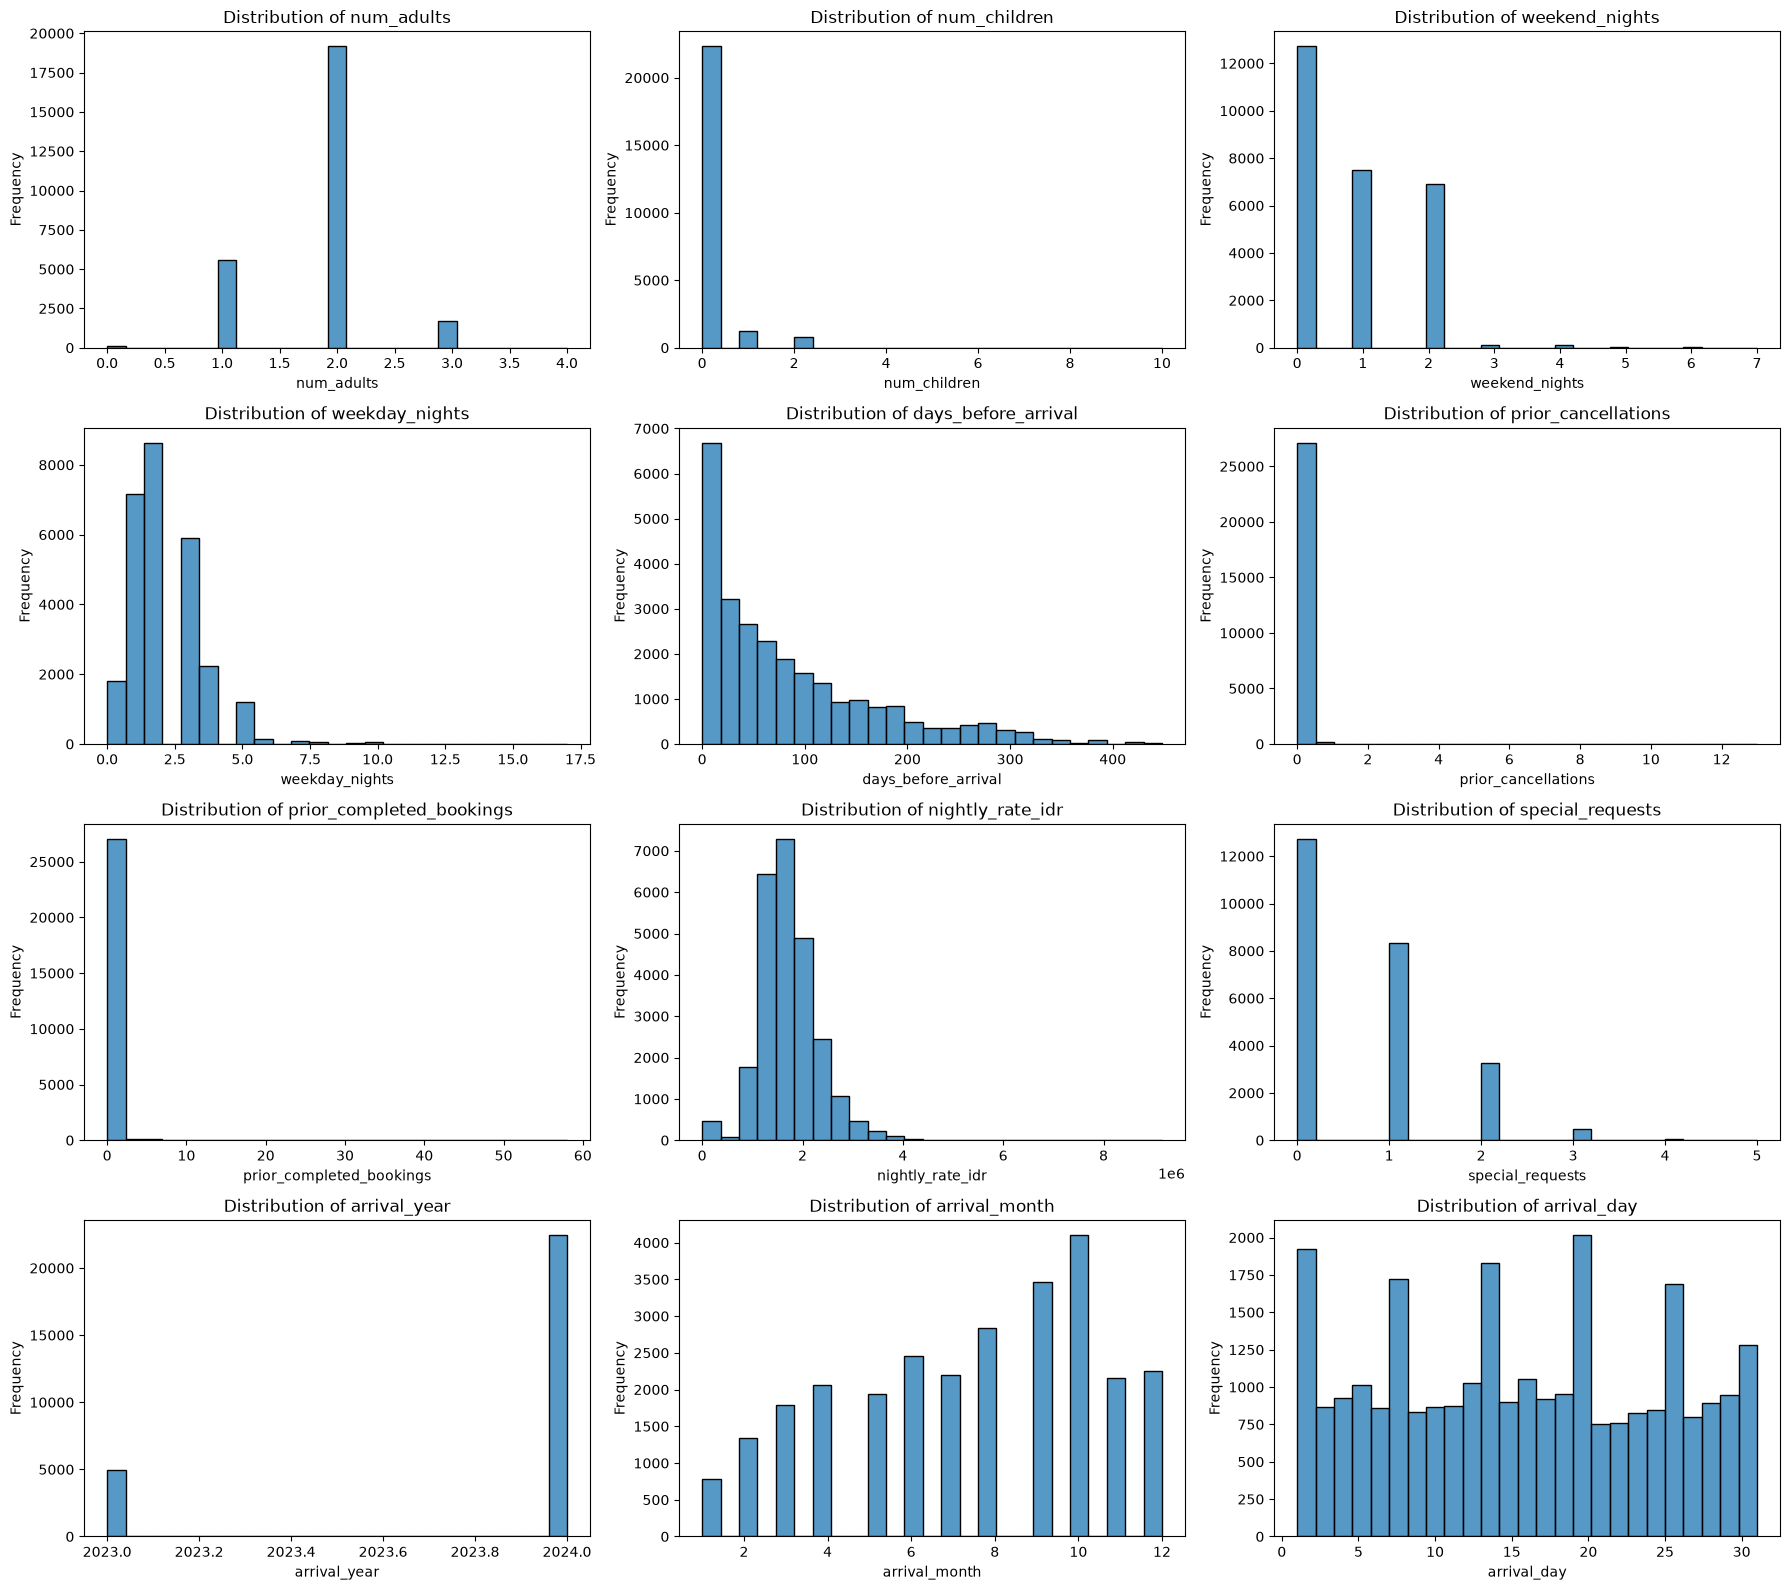

In [58]:
# ==========================================
# DISTRIBUSI DATA NUMERIK
# ==========================================

print("\n=============================================")
print("Distribusi Data Numerik")
print("=============================================\n")

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
    sns.histplot(data=train_df, x=col, bins=25, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

for i in range(len(numerical_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()


Distribusi Data Kategorikal



C:\Users\aldie\AppData\Local\Temp\ipykernel_26804\2404341477.py:12: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  sns.countplot(x=train_df[col].fillna("Missing").astype(str), ax=axes[i])


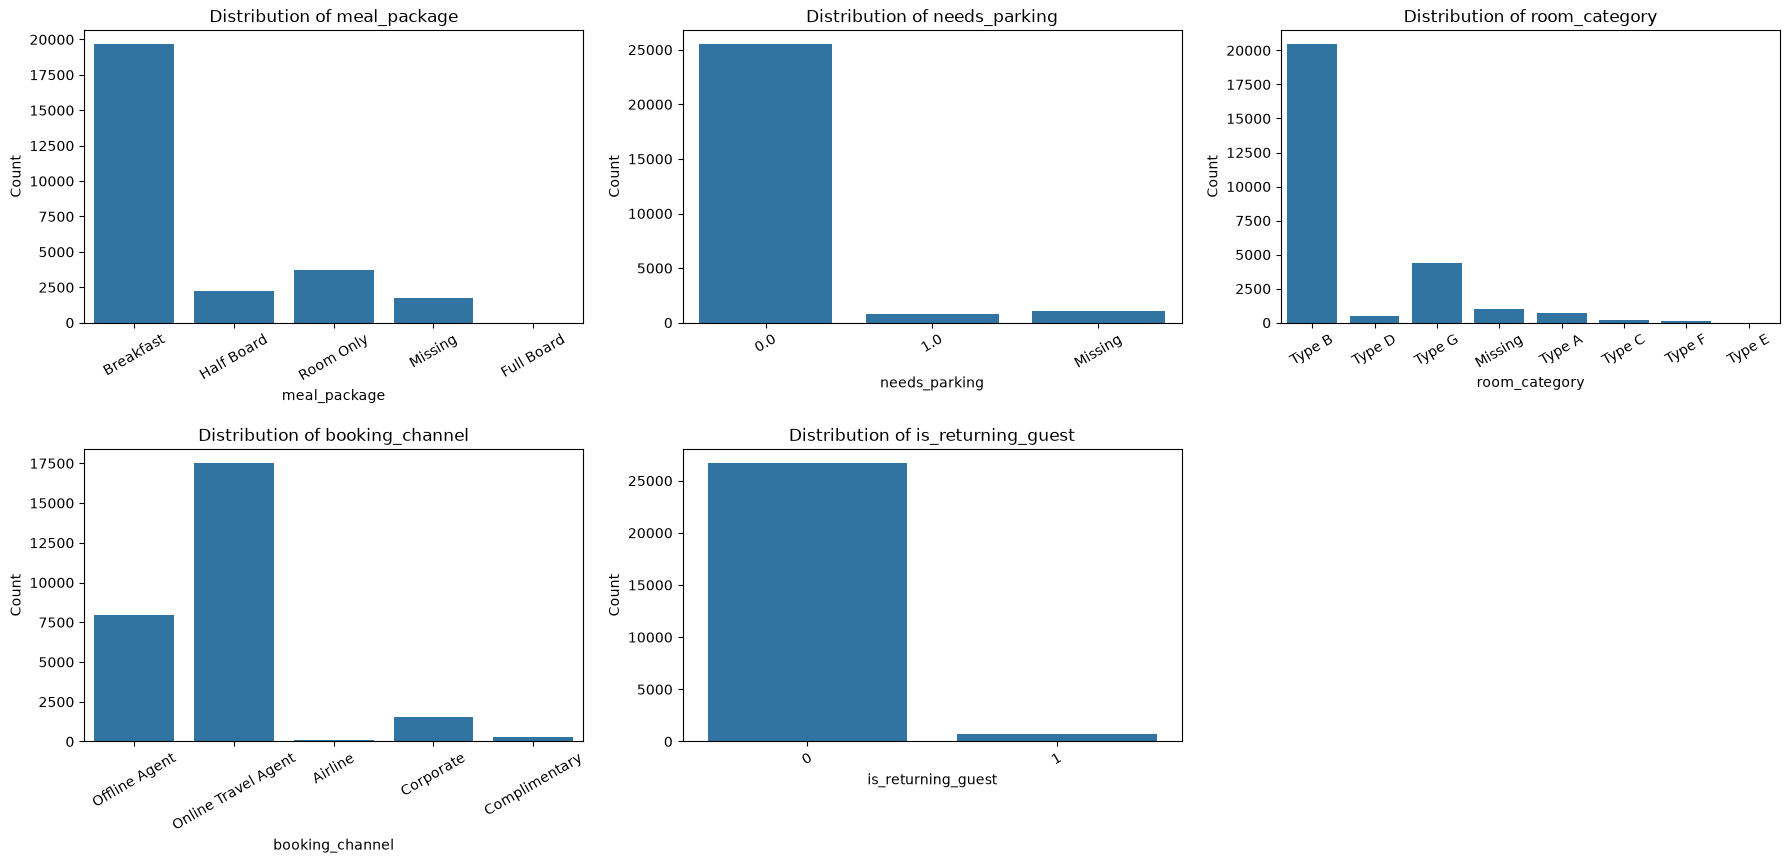

In [59]:
# ==========================================
# DISTRIBUSI DATA KATEGORIKAL
# ==========================================

print("\n=============================================")
print("Distribusi Data Kategorikal")
print("=============================================\n")

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)
axes = axes.flatten()
for i, col in enumerate(categorical_cols):
    sns.countplot(x=train_df[col].fillna("Missing").astype(str), ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=30)

for i in range(len(categorical_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()


Hubungan Data Numerik dengan Target



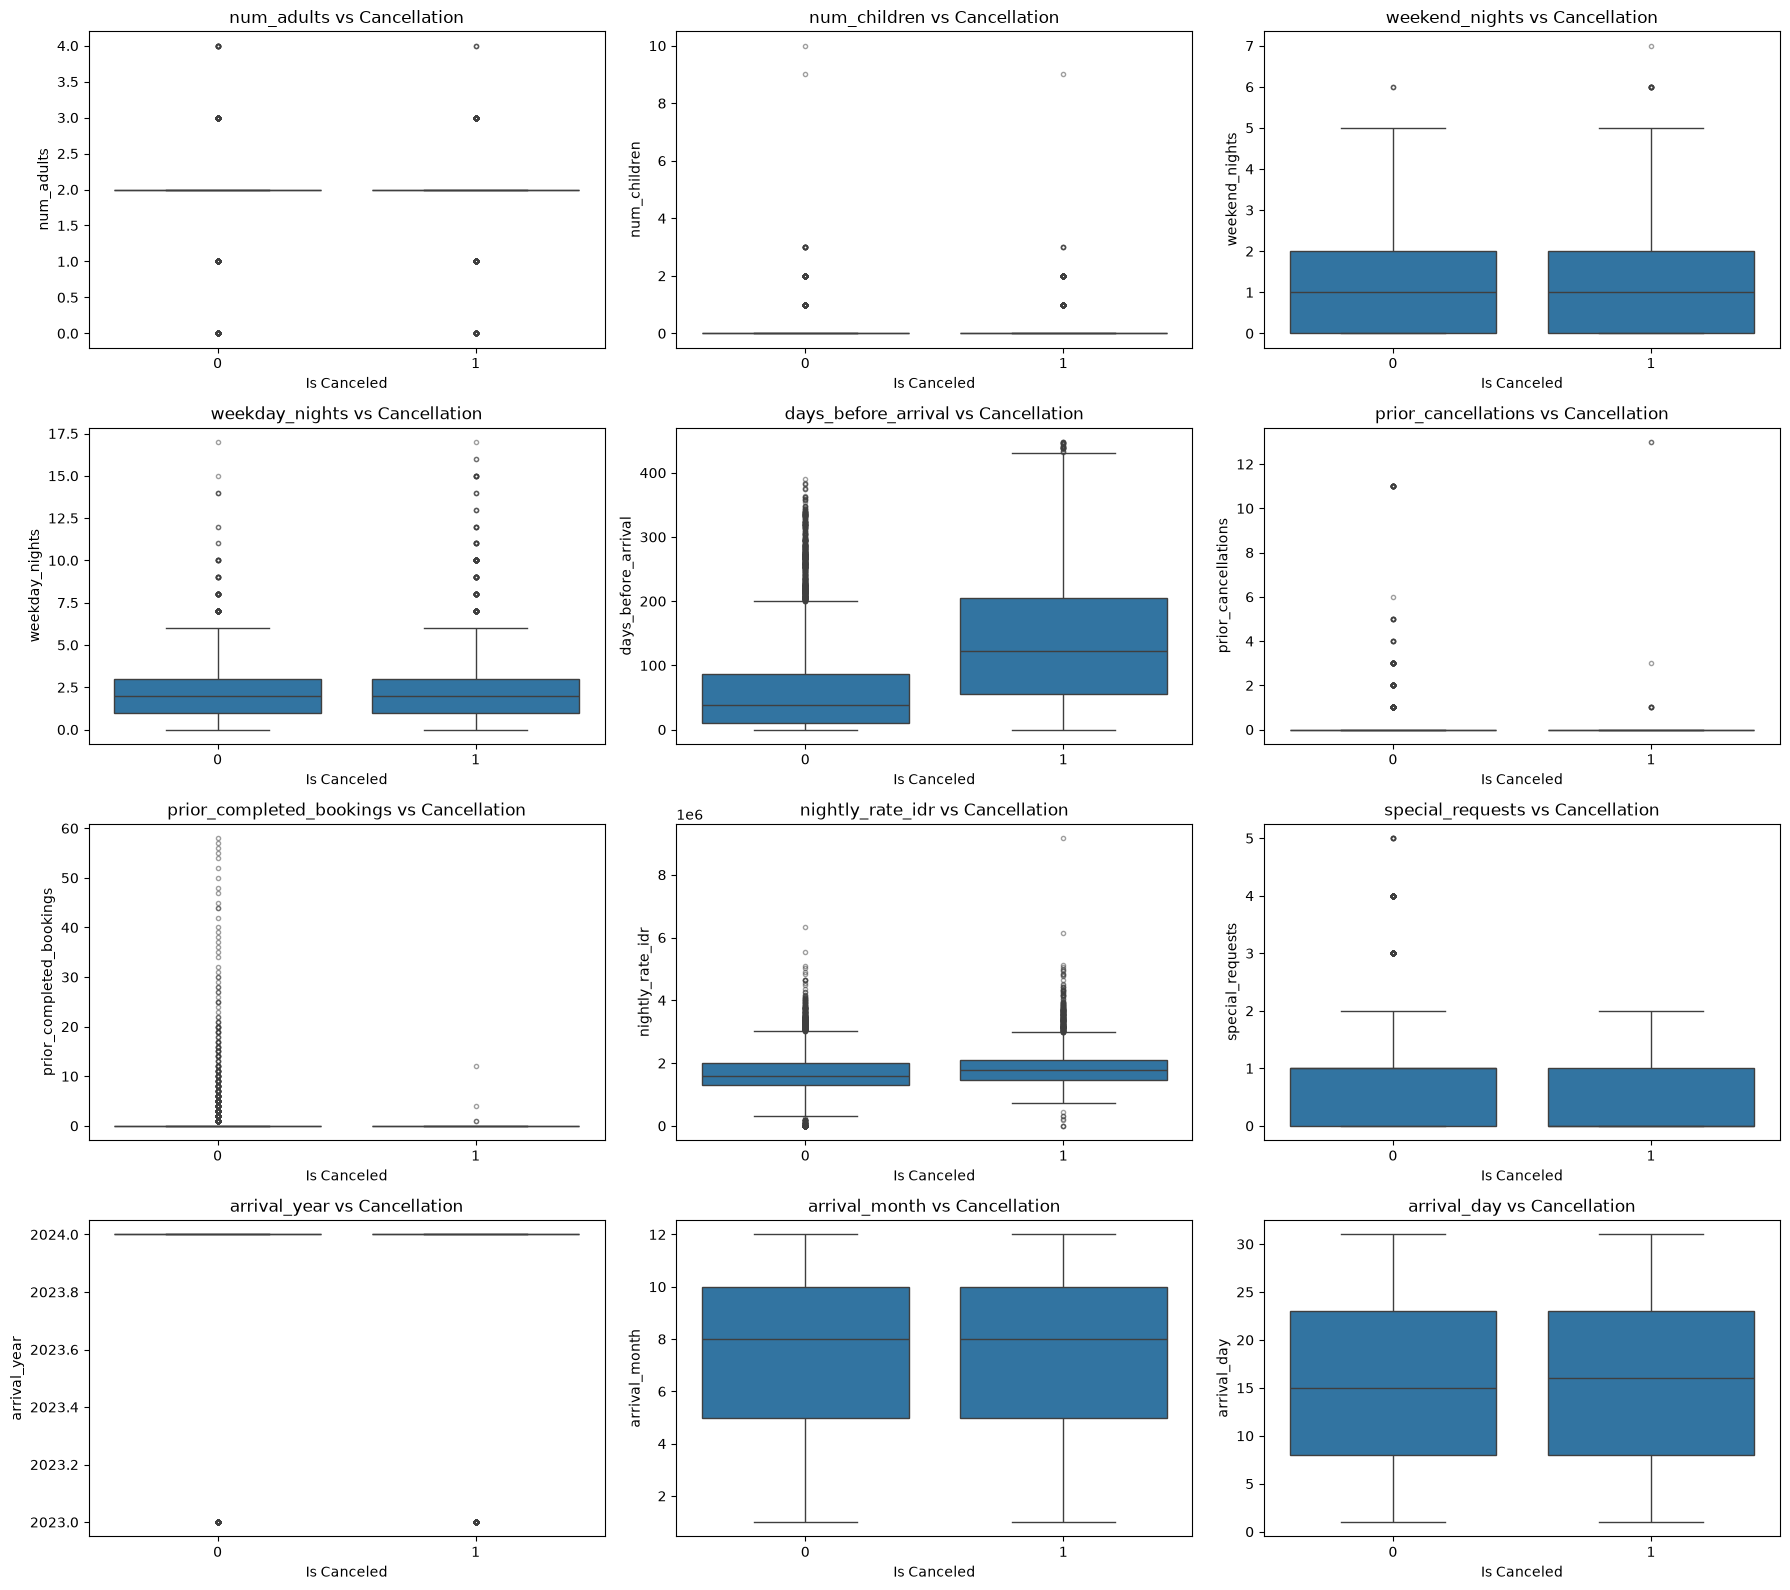

In [60]:
# ==========================================
# HUBUNGAN DATA NUMERIK DENGAN TARGET
# ==========================================

print("\n=============================================")
print("Hubungan Data Numerik dengan Target")
print("=============================================\n")

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
    sns.boxplot(data=train_df, x="is_canceled", y=col, showfliers=True,
        flierprops = {
            "marker": "o",
            "markersize": 3,
            "alpha": 0.5
        },
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs Cancellation")
    axes[i].set_xlabel("Is Canceled")
    axes[i].set_ylabel(col)

for i in range(len(numerical_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()


Hubungan Data Kategorikal dengan Target



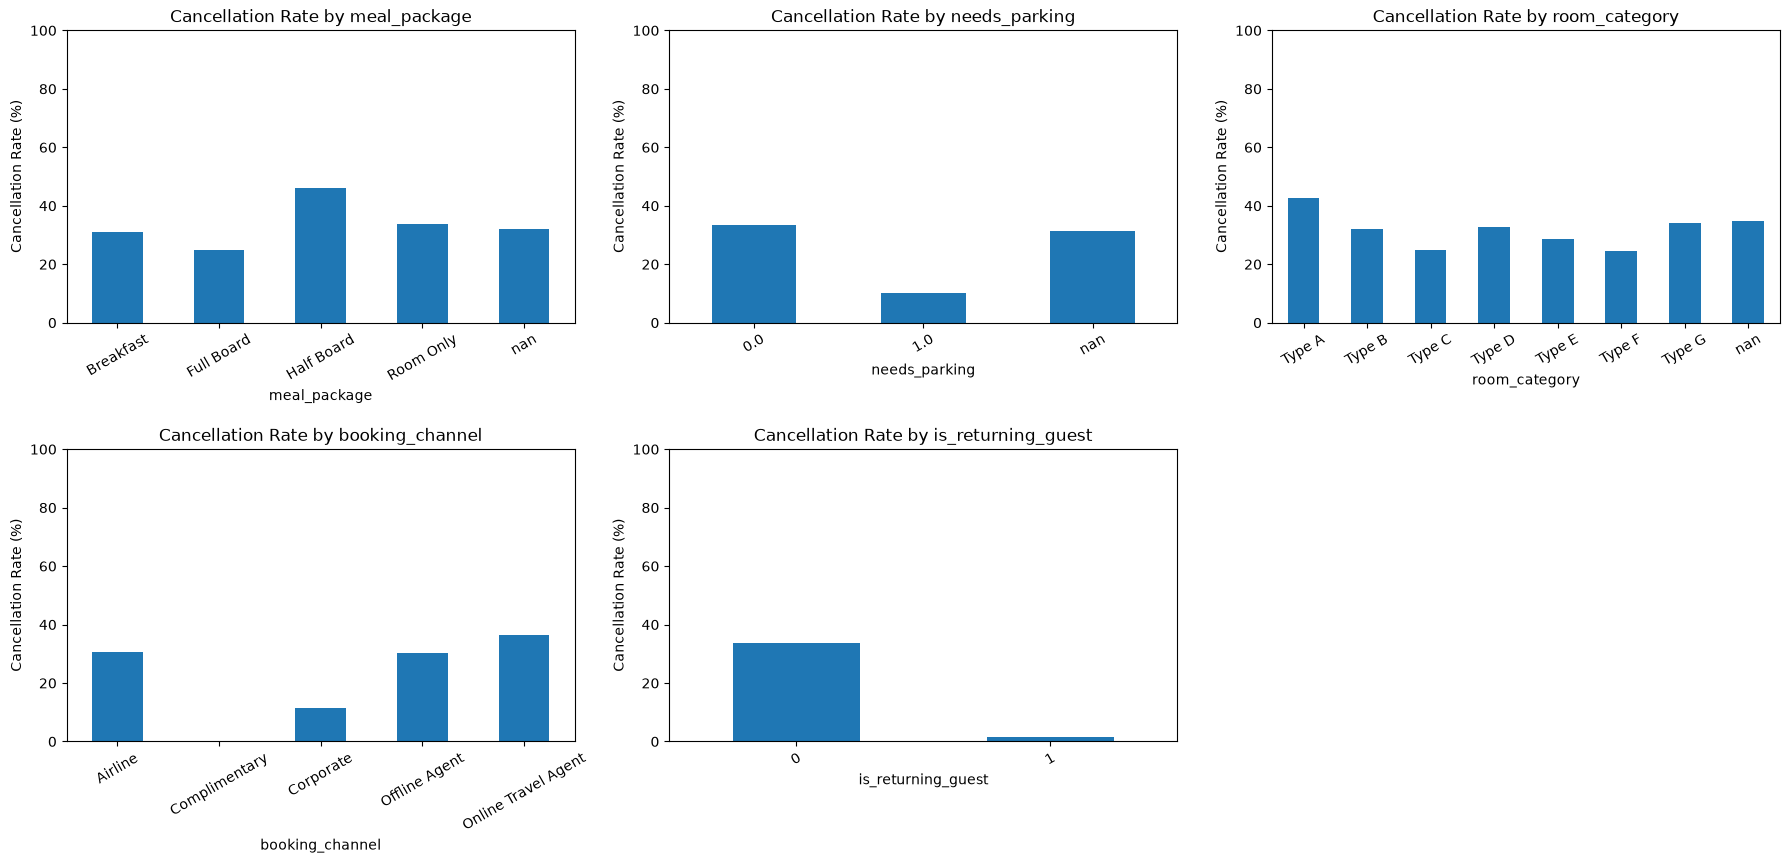

In [61]:
# ==========================================
# HUBUNGAN DATA KATEGORIKAL DENGAN TARGET
# ==========================================

print("\n=============================================")
print("Hubungan Data Kategorikal dengan Target")
print("=============================================\n")

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)
axes = axes.flatten()
for i, col in enumerate(categorical_cols):
    cancel_rate = (train_df.groupby(col, dropna=False)["is_canceled"].mean().mul(100))
    cancel_rate.plot(kind="bar", ax=axes[i])
    axes[i].set_title(f"Cancellation Rate by {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Cancellation Rate (%)")
    axes[i].tick_params(axis="x", rotation=30)
    axes[i].set_ylim(0, 100)

for i in range(len(categorical_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()


Hubungan Antaratribut Numerik dengan Heatmap



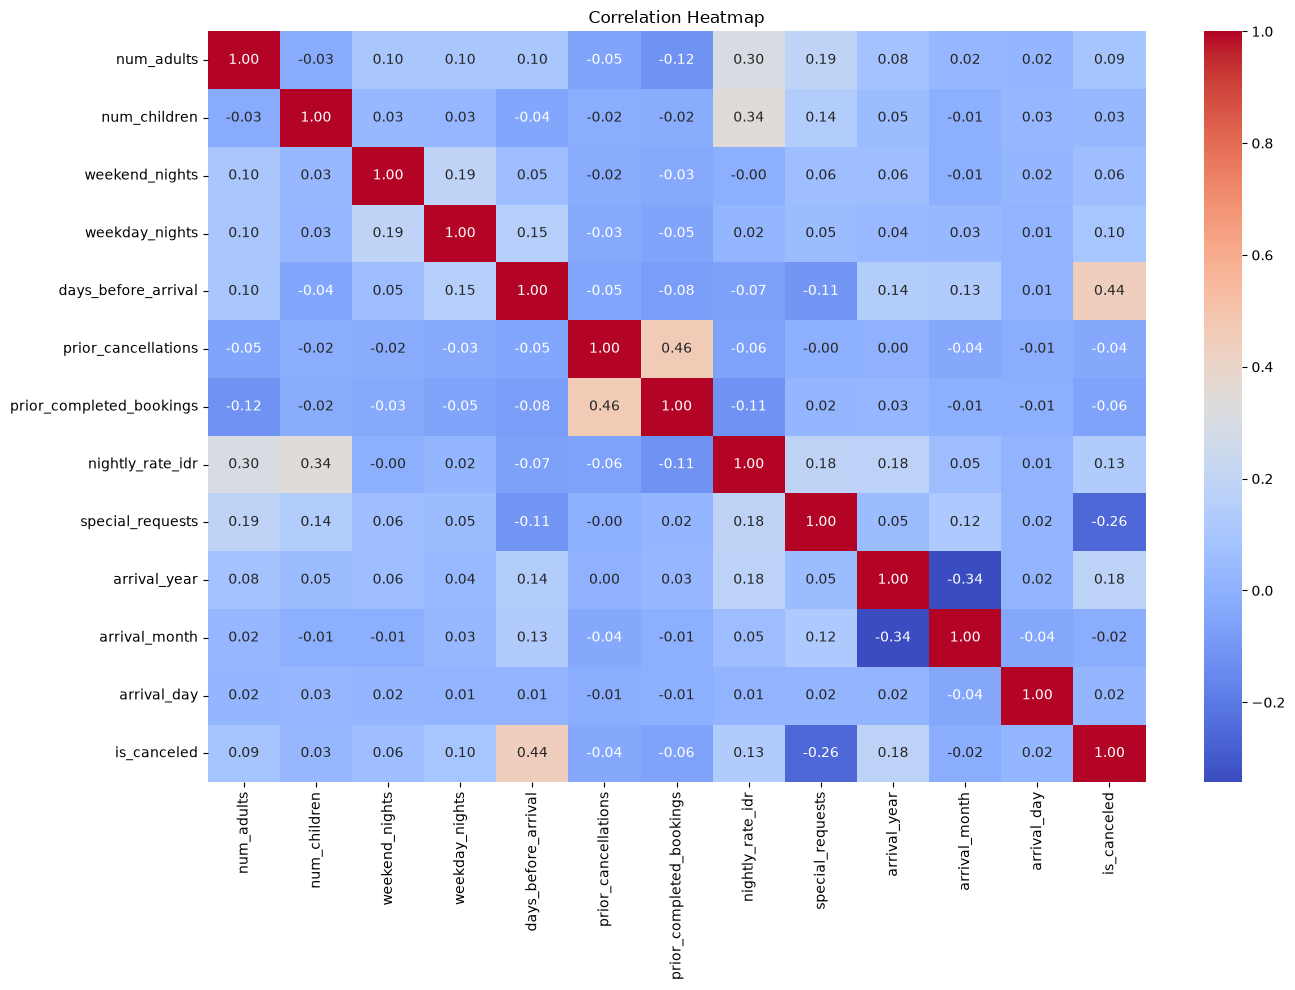

,Feature,Correlation
0,days_before_arrival,0.440316
1,special_requests,-0.257996
2,arrival_year,0.179826
3,nightly_rate_idr,0.134092
4,is_returning_guest,-0.107207
5,weekday_nights,0.097226
6,num_adults,0.088446
7,needs_parking,-0.085504
8,weekend_nights,0.060797
9,prior_completed_bookings,-0.058894


In [62]:
# ==========================================
# KORELASI ANTARATRIBUT NUMERIK
# ==========================================

print("\n=============================================")
print("Hubungan Antaratribut Numerik dengan Heatmap")
print("=============================================\n")
# Korelasi antar atribut pada Heatmap
corr_cols = numerical_cols + target_cols
correlation = train_df[corr_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Urutan korelasi atribut dengan target dari yg terbesar
correlation = (train_df.select_dtypes(include="number").drop(columns="is_canceled").corrwith(train_df["is_canceled"]).sort_values(key=abs, ascending=False))
correlation_table = correlation.rename_axis("Feature").reset_index(name="Correlation")
display(correlation_table)

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [63]:
# ==========================================
# Check missing values
# ==========================================

# Memeriksa missing values pada train dan test
print("\n=============================================")
print("Missing Values")
print("=============================================\n")

missing_train = train_df.isnull().sum()
missing_test = test_df.isnull().sum()

print(f"Missing Values - Train")
display(missing_train.to_frame(name="count_missing"))

print(f"Missing Values - Test")
display(missing_train.to_frame(name="count_missing"))


Missing Values

Missing Values - Train


,count_missing
num_adults,809
num_children,3035
weekend_nights,0
weekday_nights,0
meal_package,1760
needs_parking,1082
room_category,1002
days_before_arrival,1123
arrival_year,0
arrival_month,0


Missing Values - Test


,count_missing
num_adults,809
num_children,3035
weekend_nights,0
weekday_nights,0
meal_package,1760
needs_parking,1082
room_category,1002
days_before_arrival,1123
arrival_year,0
arrival_month,0


In [64]:
# ==========================================
# Check Duplicate Value
# ==========================================

# Memeriksa data-data yangduplikat
print("\n=============================================")
print("Duplicate Data")
print("=============================================\n")

display(train_df[train_df.duplicated(keep= False)])
print(f"Duplicated Train: {train_df.duplicated().sum()}")
display(train_df[train_df.duplicated(keep= False)])
print(f"Duplicated Test: {test_df.duplicated().sum()}")


Duplicate Data



,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
320,2.0,0.0,0,2,Half Board,0.0,Type B,77.0,2023,9,18,Offline Agent,0,0,0,1763000.0,0.0,0
932,2.0,0.0,0,3,Breakfast,0.0,Type B,38.0,2024,10,12,Offline Agent,0,0,0,NaN,0.0,0
1003,2.0,0.0,0,1,Breakfast,0.0,Type B,39.0,2023,10,23,Online Travel Agent,0,0,0,0.0,0.0,0
1109,1.0,0.0,0,3,Breakfast,0.0,Type B,NaN,2024,6,13,Offline Agent,0,0,0,NaN,0.0,0
1134,2.0,0.0,1,1,Breakfast,0.0,Type B,184.0,2024,5,1,Offline Agent,0,0,0,NaN,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26440,1.0,0.0,0,3,Breakfast,0.0,Type B,164.0,2024,10,31,Offline Agent,0,0,0,1763000.0,0.0,1
26766,2.0,0.0,0,2,Half Board,0.0,Type B,351.0,2024,9,12,Offline Agent,0,0,0,NaN,1.0,1
26912,2.0,0.0,0,2,Half Board,0.0,Type B,76.0,2023,9,18,Offline Agent,0,0,0,NaN,0.0,0
27050,2.0,0.0,2,1,Half Board,0.0,Type B,143.0,2023,8,29,Offline Agent,0,0,0,NaN,0.0,0


Duplicated Train: 64


,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
320,2.0,0.0,0,2,Half Board,0.0,Type B,77.0,2023,9,18,Offline Agent,0,0,0,1763000.0,0.0,0
932,2.0,0.0,0,3,Breakfast,0.0,Type B,38.0,2024,10,12,Offline Agent,0,0,0,NaN,0.0,0
1003,2.0,0.0,0,1,Breakfast,0.0,Type B,39.0,2023,10,23,Online Travel Agent,0,0,0,0.0,0.0,0
1109,1.0,0.0,0,3,Breakfast,0.0,Type B,NaN,2024,6,13,Offline Agent,0,0,0,NaN,0.0,0
1134,2.0,0.0,1,1,Breakfast,0.0,Type B,184.0,2024,5,1,Offline Agent,0,0,0,NaN,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26440,1.0,0.0,0,3,Breakfast,0.0,Type B,164.0,2024,10,31,Offline Agent,0,0,0,1763000.0,0.0,1
26766,2.0,0.0,0,2,Half Board,0.0,Type B,351.0,2024,9,12,Offline Agent,0,0,0,NaN,1.0,1
26912,2.0,0.0,0,2,Half Board,0.0,Type B,76.0,2023,9,18,Offline Agent,0,0,0,NaN,0.0,0
27050,2.0,0.0,2,1,Half Board,0.0,Type B,143.0,2023,8,29,Offline Agent,0,0,0,NaN,0.0,0


Duplicated Test: 3


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [65]:
# ==========================================
# TRAINING AND VALIDATION SPLIT
# ==========================================

# Jumlah fold untuk Cross-Validation
N_SPLITS = 5

selected_cols = numerical_cols + categorical_cols

X = train_df[selected_cols].copy()
y = train_df["is_canceled"].copy()

# Test Kaggle hanya untuk submission
x_test = test_df[selected_cols].copy()

# ==========================================
# STRATIFIED K-FOLD
# ==========================================

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
train_idx, val_idx = next(cv.split(X, y))
x_train = X.iloc[train_idx].copy()
x_val = X.iloc[val_idx].copy()
y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

# ==========================================
# MENAMPILKAN HASIL
# ==========================================

print("\n=============================================")
print("Training and Validation Strategy")
print("=============================================\n")

print("Training Data  :", x_train.shape)
print("Validation Data:", x_val.shape)
print("Test Data      :", x_test.shape)

# ==========================================
# TRAINING AND VALIDATION SPLIT 80:20
# ==========================================

# from sklearn.model_selection import train_test_split

# selected_cols = numerical_cols + categorical_cols

# # Fitur dan target train.csv
# X = train_df[selected_cols].copy()
# y = train_df["is_canceled"].copy()

# # Data test Kaggle
# x_test = test_df[selected_cols].copy()

# # Split 80% training dan 20% validation
# x_train, x_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=CFG.SEED, stratify=y)

# print("Training Data  :", x_train.shape)
# print("Validation Data:", x_val.shape)
# print("Test Kaggle    :", x_test.shape)

# print("\nDistribusi Target Training:")
# display(y_train.value_counts(normalize=True).to_frame("Persentase"))

# print("Distribusi Target Validation:")
# display(y_val.value_counts(normalize=True).to_frame("Persentase"))

# # Memastikan tidak ada baris yang overlap
# overlap = set(x_train.index).intersection(x_val.index)

# print("Jumlah baris overlap:", len(overlap))
# assert len(overlap) == 0


Training and Validation Strategy

Training Data  : (21898, 17)
Validation Data: (5475, 17)
Test Data      : (6844, 17)


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [66]:
# ==========================================
# SELECT DATA
# ==========================================

# Memilih atribut yang digunakan sebagai fitur
display(x_train.head())
display(x_val.head())
display(x_test.head())

,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,arrival_year,arrival_month,arrival_day,meal_package,needs_parking,room_category,booking_channel,is_returning_guest
0,2.0,NaN,1,2,88.0,0,0,1330000.0,0.0,2024,4,3,Breakfast,0.0,Type B,Offline Agent,0
1,2.0,0.0,2,1,120.0,0,0,NaN,0.0,2023,8,1,Half Board,0.0,Type D,Offline Agent,0
2,3.0,0.0,1,2,209.0,0,0,2099000.0,0.0,2024,8,28,Breakfast,0.0,Type G,Online Travel Agent,0
3,2.0,1.0,2,1,93.0,0,0,1693000.0,2.0,2024,8,13,Breakfast,0.0,Type G,Online Travel Agent,0
4,2.0,0.0,0,1,14.0,0,0,2010000.0,2.0,2024,9,1,Room Only,0.0,Type B,Online Travel Agent,0


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,arrival_year,arrival_month,arrival_day,meal_package,needs_parking,room_category,booking_channel,is_returning_guest
15,2.0,0.0,0,1,9.0,0,0,1312000.0,NaN,2023,8,22,Room Only,0.0,Type B,Online Travel Agent,0
16,2.0,0.0,0,2,17.0,0,0,2194000.0,1.0,2024,8,18,Breakfast,0.0,Type B,Online Travel Agent,0
25,1.0,0.0,1,1,3.0,0,3,1307000.0,NaN,2024,7,3,Breakfast,0.0,Type B,Corporate,1
31,NaN,0.0,0,4,171.0,0,0,1909000.0,0.0,2024,12,6,Breakfast,0.0,Type G,Online Travel Agent,0
32,3.0,0.0,1,3,12.0,0,0,1163000.0,0.0,2024,3,9,Breakfast,0.0,Type G,Offline Agent,0


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,arrival_year,arrival_month,arrival_day,meal_package,needs_parking,room_category,booking_channel,is_returning_guest
0,2.0,0.0,0,1,217.0,0,0,1299000.0,0.0,2024,8,11,Breakfast,0.0,Type B,Offline Agent,0
1,2.0,0.0,1,2,190.0,0,0,2010000.0,0.0,2024,6,19,Breakfast,0.0,Type B,Online Travel Agent,0
2,2.0,0.0,1,2,124.0,0,0,1921000.0,1.0,2024,5,12,Breakfast,0.0,Type B,Online Travel Agent,0
3,NaN,0.0,2,4,0.0,0,0,1451000.0,0.0,2024,1,2,Half Board,0.0,Type B,Online Travel Agent,0
4,2.0,1.0,2,3,44.0,0,0,1225000.0,2.0,2023,11,1,Breakfast,0.0,Type G,Offline Agent,0


In [67]:
# ==========================================
# Transformer and Pipeline List
# ==========================================

transformer_list = []
pipeline_list = []
_transformer_groups = {}

def reset_pipeline_lists():
    global transformer_list
    global pipeline_list
    global _transformer_groups

    transformer_list = []
    pipeline_list = []
    _transformer_groups = {}

def register_transformer(columns, step_name, transformer):
    columns = list(columns)
    key = tuple(columns)

    if key not in _transformer_groups:
        group_index = len(_transformer_groups) + 1

        _transformer_groups[key] = {
            "name": f"group_{group_index}",
            "columns": columns,
            "steps": []
        }

    group = _transformer_groups[key]
    group["steps"].append((step_name, transformer))

    transformer_list.clear()
    for transformer_group in _transformer_groups.values():
        transformer_list.append((transformer_group["name"], Pipeline(transformer_group["steps"]), transformer_group["columns"]))

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [68]:
# ==========================================
# MISSING VALUES
# ==========================================

# Identifikasi kolom yg memiliki missing values
numeric_missing_cols = [
    "num_adults",
    "num_children",
    "days_before_arrival",
    "nightly_rate_idr",
    "special_requests"
]

categorical_missing_cols = [
    "meal_package",
    "room_category"
]

binary_missing_cols = [ 
    "needs_parking"
]

# Handle missing values
def impute_data(columns, strategy="median"):
    imputer = SimpleImputer(strategy=strategy)
    register_transformer(columns=columns, step_name="imputer", transformer=imputer)

### Duplicates

This part covers repeated records.

In [69]:
# ==========================================
# DUPLICATE DATA
# ==========================================

print("\n=============================================")
print("Duplicate Data pada Training Data")
print("=============================================\n")

# Memeriksa duplikat pada data yang sudah dibersihkan
duplicate_train = x_train.duplicated().sum()
print("Jumlah data duplikat berdasarkan fitur:", duplicate_train)

# Memeriksa duplikat berdasarkan fitur dan target
train_check = x_train.copy()
train_check["is_canceled"] = y_train

duplicate_full = train_check.duplicated().sum()
print("Jumlah data duplikat berdasarkan fitur dan target:", duplicate_full)

# Menampilkan data duplikat
if duplicate_full > 0:
    print("\nData yang duplikat:")
    display(train_check[train_check.duplicated(keep=False)].head(10))
else:
    print("\nTidak ditemukan data duplikat.")

# Handle missing values
def handle_duplicate():
    pass



Duplicate Data pada Training Data

Jumlah data duplikat berdasarkan fitur: 42
Jumlah data duplikat berdasarkan fitur dan target: 41

Data yang duplikat:


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,arrival_year,arrival_month,arrival_day,meal_package,needs_parking,room_category,booking_channel,is_returning_guest,is_canceled
320,2.0,0.0,0,2,77.0,0,0,1763000.0,0.0,2023,9,18,Half Board,0.0,Type B,Offline Agent,0,0
932,2.0,0.0,0,3,38.0,0,0,NaN,0.0,2024,10,12,Breakfast,0.0,Type B,Offline Agent,0,0
1003,2.0,0.0,0,1,39.0,0,0,0.0,0.0,2023,10,23,Breakfast,0.0,Type B,Online Travel Agent,0,0
1109,1.0,0.0,0,3,NaN,0,0,NaN,0.0,2024,6,13,Breakfast,0.0,Type B,Offline Agent,0,0
1134,2.0,0.0,1,1,184.0,0,0,NaN,1.0,2024,5,1,Breakfast,0.0,Type B,Offline Agent,0,0
1317,1.0,0.0,2,1,6.0,0,0,NaN,0.0,2024,2,28,Breakfast,0.0,Type B,Offline Agent,0,1
1626,1.0,0.0,0,3,155.0,0,0,NaN,0.0,2024,1,19,Breakfast,0.0,Type B,Offline Agent,0,0
2652,1.0,0.0,0,2,187.0,0,0,1599000.0,0.0,2024,6,23,Breakfast,0.0,Type B,Offline Agent,0,0
2806,1.0,0.0,0,2,162.0,0,0,NaN,0.0,2023,10,2,Breakfast,0.0,Type B,Offline Agent,0,0
3030,1.0,0.0,0,2,163.0,0,0,NaN,0.0,2023,10,2,Breakfast,0.0,Type B,Offline Agent,0,0


### Outliers

This part covers values far from the rest of the data.

In [70]:
# ==========================================
# OUTLIERS
# ==========================================

# Menghitung outlier dengan IQR
print("\n=============================================")
print("Outlier Detection (IQR)")
print("=============================================\n")

x_outlier = x_train.copy()
outlier_results = []

for col in numerical_cols:
    Q1 = x_outlier[col].quantile(0.25)
    Q3 = x_outlier[col].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = ((x_outlier[col] < batas_bawah) | (x_outlier[col] > batas_atas)).sum()
    outlier_results.append({
        "Atribut": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Outlier": jumlah_outlier
    })

outlier_table = pd.DataFrame(outlier_results)
display(outlier_table.round(2))

# Handle missing values
def handle_outlier():
    pass


Outlier Detection (IQR)



,Atribut,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier
0,num_adults,2.0,2.0,0.0,2.0,2.0,5898
1,num_children,0.0,0.0,0.0,0.0,0.0,1598
2,weekend_nights,0.0,2.0,2.0,-3.0,5.0,14
3,weekday_nights,1.0,3.0,2.0,-2.0,6.0,206
4,days_before_arrival,17.0,127.0,110.0,-148.0,292.0,717
5,prior_cancellations,0.0,0.0,0.0,0.0,0.0,173
6,prior_completed_bookings,0.0,0.0,0.0,0.0,0.0,470
7,nightly_rate_idr,1340000.0,2019000.0,679000.0,321500.0,3037500.0,930
8,special_requests,0.0,1.0,1.0,-1.5,2.5,448
9,arrival_year,2024.0,2024.0,0.0,2024.0,2024.0,3910


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [71]:
# Write your code here

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

This part covers new attributes derived from existing ones.

In [72]:
# ==========================================
# ATTRIBUTE CONSTRUCTION
# ==========================================

# Membuat atribut baru dari fitur yang sudah ada
def add_features(data, column_name, columns):
    if data is None:
        feature_transformer = FunctionTransformer(add_features, kw_args={"column_name": column_name, "columns": columns}, validate=False)
        pipeline_list.append((f"add_{column_name}", feature_transformer))
        return None

    result = data.copy()
    result[column_name] = result[columns].sum(axis=1)
    return result

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [73]:
# ==========================================
# FEATURE SCALING
# ==========================================

# Handle scaling
def scaling(columns, scale_type="robust"):
    if scale_type == "robust":
        scaler = RobustScaler()

    elif scale_type == "standard":
        scaler = StandardScaler()

    elif scale_type == "minmax":
        scaler = MinMaxScaler()

    register_transformer(columns=columns, step_name="scaler", transformer=scaler)

### Encoding

This part covers the numeric representation of categorical attributes.

In [74]:
# ==========================================
# ENCODING
# ==========================================

# Handle encoding
def encoding(columns, encode_type="onehot"):
    columns = list(columns)

    if encode_type == "onehot":
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    elif encode_type == "ordinal":
        encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)

    register_transformer(columns=columns, step_name="encoder", transformer=encoder)

### Discretization

This part covers numeric attributes grouped into bins so they can be treated as categories.

In [75]:
# ==========================================
# DISCRETIZATION
# ==========================================

# Handle discretization (fitur numerik dibagi ke n_bins bin berdasarkan kuantil)
def discretization(columns, n_bins=12):
    discretizer = KBinsDiscretizer(n_bins=n_bins, encode="ordinal", strategy="quantile", subsample=None)
    register_transformer(columns=columns, step_name="discretizer", transformer=discretizer)

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [76]:
# ==========================================
# DIMENSIONALITY REDUCTION (PCA)
# ==========================================

def pca(n_components=0.95):
    if n_components is None:
        pipeline_list.append(("pca", "passthrough"))
        return

    pca_model = PCA(n_components=n_components)
    pipeline_list.append(("pca", pca_model))

## Class Balance

This part covers the proportion of each class in the training data.

In [77]:
# ==========================================
# CLASS BALANCE
# ==========================================

def balancing(method=None):
    if method is None:
        return

    if method == "smote":
        sampler = SMOTE(random_state=42)

    elif method == "undersample":
        sampler = RandomUnderSampler(random_state=42)

    pipeline_list.append(("balancing", sampler))

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [78]:
# ==========================================
# FORMAT DATA
# ==========================================

def format_data():
    formatter = FunctionTransformer(np.asarray, kw_args={"dtype": float}, validate=False)
    pipeline_list.append(("format_data", formatter))

---

# Preparation Pipeline <a name="6"></a>

---

The pipeline combines the preparation steps so they run in one consistent order.

In [79]:
# ==========================================
# Preperation Pipeline
# ==========================================

src_dir = str(CFG.PROJECT_DIR / "src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

def knn_pipeline():
    reset_pipeline_lists()
    num_features = numerical_cols

    cat_features = [
        "meal_package",
        "room_category",
        "booking_channel"
    ]

    binary_features = [
        "needs_parking",
        "is_returning_guest"
    ]

    add_features(None, "total_nights", ["weekend_nights", "weekday_nights"])
    add_features(None, "total_guests", ["num_adults", "num_children"])

    impute_data(num_features, strategy="median")
    impute_data(cat_features, strategy="most_frequent")
    impute_data(binary_features, strategy="most_frequent")

    scaling(num_features, scale_type="robust")

    encoding(cat_features, encode_type="onehot")

    column_transformer = ColumnTransformer(transformers=list(transformer_list), remainder="drop", verbose_feature_names_out=False)
    pipeline_list.append(("column_transformer", column_transformer))

    pca(n_components=None)
    format_data()

    return Pipeline(steps=list(pipeline_list))

In [ ]:
# Menjalankan Pipeline
preparation_pipeline = knn_pipeline()

x_train_prepared = (preparation_pipeline.fit_transform(x_train))
x_val_prepared = (preparation_pipeline.transform(x_val))
x_test_prepared = (preparation_pipeline.transform(x_test))

In [ ]:
# ==========================================
# Preperation Pipeline - Naive Bayes
# ==========================================

def naive_bayes_pipeline(n_bins=12):
    reset_pipeline_lists()

    # Fitur numerik kontinu: dibagi ke n_bins bin kuantil
    bin_features = [
        "days_before_arrival",
        "nightly_rate_idr"
    ]

    # Fitur numerik lain bernilai sedikit: tiap nilai diperlakukan sebagai kategori
    ordinal_features = [col for col in numerical_cols if col not in bin_features]

    cat_features = [
        "meal_package",
        "room_category",
        "booking_channel"
    ]

    binary_features = [
        "needs_parking",
        "is_returning_guest"
    ]

    impute_data(bin_features, strategy="median")
    impute_data(ordinal_features, strategy="median")
    impute_data(cat_features, strategy="most_frequent")
    impute_data(binary_features, strategy="most_frequent")

    discretization(bin_features, n_bins=n_bins)

    encoding(ordinal_features, encode_type="ordinal")
    encoding(cat_features, encode_type="ordinal")

    column_transformer = ColumnTransformer(transformers=list(transformer_list), remainder="drop", verbose_feature_names_out=False)
    pipeline_list.append(("column_transformer", column_transformer))

    format_data()

    return Pipeline(steps=list(pipeline_list))

In [ ]:
# Menjalankan Pipeline Naive Bayes
nb_preparation_pipeline = naive_bayes_pipeline()

x_train_nb = nb_preparation_pipeline.fit_transform(x_train)
x_val_nb = nb_preparation_pipeline.transform(x_val)
x_test_nb = nb_preparation_pipeline.transform(x_test)

print("Training Data  :", x_train_nb.shape)
print("Validation Data:", x_val_nb.shape)
print("Test Data      :", x_test_nb.shape)

In [ ]:
# # ==========================================
# # PREPARATION PIPELINE -- Yg bagus di leaderboard
# # ==========================================

# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
# from sklearn.impute import SimpleImputer
# import numpy as np

# print("\n=============================================")
# print("Preparation Pipeline")
# print("=============================================\n")

# format_data()
# # Menentukan jenis fitur
# num_features = numerical_cols 

# cat_features = [
#     "meal_package",
#     "room_category",
#     "booking_channel"
# ]

# binary_features = [
#     "needs_parking",
#     "is_returning_guest"
# ]

# # Missing Value Handling
# imputer = ColumnTransformer([
#     ("num", SimpleImputer(strategy="median"), num_features),
#     ("cat", SimpleImputer(strategy="most_frequent"), cat_features),
#     ("binary", SimpleImputer(strategy="most_frequent"), binary_features)
# ], verbose_feature_names_out=False).set_output(transform="pandas")

# preprocessor = ColumnTransformer([
#     ("num", RobustScaler(), num_features),
#     ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
#     ("binary", "passthrough", binary_features)
# ])

# # Menggabungkan Preparation Pipeline
# preparation_pipeline = Pipeline([
#     ("imputer", imputer),
#     ("attribute_construction", FunctionTransformer(add_features)),
#     ("preprocessing", preprocessor),
#     ("pca", "passthrough")
# ])


# # Menerapkan Pipeline pada data awal
# X_train_prepared = preparation_pipeline.fit_transform(x_train)
# X_val_prepared = preparation_pipeline.transform(x_val)
# X_test_prepared = preparation_pipeline.transform(x_test)

# # Memeriksa hasil
# print("Training Data  :", X_train_prepared.shape)
# print("Validation Data:", X_val_prepared.shape)
# print("Test Kaggle    :", X_test_prepared.shape)

# print("\nMissing Values:")
# print("Train:", np.isnan(X_train_prepared).sum())
# print("Validation:", np.isnan(X_val_prepared).sum())
# print("Test:", np.isnan(X_test_prepared).sum())

# print("\nFeature Consistency:", X_train_prepared.shape[1] == X_val_prepared.shape[1] == X_test_prepared.shape[1])

In [ ]:
# def knn_pipeline():
#     print("\n=============================================")
#     print("KNN Preparation Pipeline")
#     print("=============================================\n")

#     num_features = numerical_cols
#     cat_features = [
#         "meal_package",
#         "room_category",
#         "booking_channel"
#     ]

#     binary_features = [
#         "needs_parking",
#         "is_returning_guest"
#     ]

#     # 1. Missing value handling
#     imputer(num_features, strategy="median")
#     imputer(cat_features, strategy="most_frequent")
#     imputer(binary_features, strategy="most_frequent")

#     # 2. Scaling fitur numerik
#     scaling(num_features, scale_type="robust")

#     # 3. One-hot encoding fitur kategorikal
#     encoding(cat_features, encode_type="onehot")

#     # Fitur biner tidak diubah (passthrough)

#     # 4. Ubah menjadi array numerik
#     format_data()

#     # 5. Validasi hasil
#     print("Training Data  :", x_train.shape)
#     print("Validation Data:", x_val.shape)
#     print("Test Data      :", x_test.shape)

#     print("\nMissing Values:")
#     print("Train     :", np.isnan(x_train).sum())
#     print("Validation:", np.isnan(x_val).sum())
#     print("Test      :", np.isnan(x_test).sum())

#     print(
#         "\nFeature Consistency:",
#         x_train.shape[1] == x_val.shape[1] == x_test.shape[1]
#     )

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.

In [ ]:
# ==========================================
# KNN MODELING
# ==========================================

def knn_modeling(k: int):
    global knn_model, y_pred_knn

    knn_model = KNN(k=k)
    knn_model.fit(x_train_prepared, y_train)
    y_pred_knn = np.array([knn_model.predict(row) for row in x_val_prepared])

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [ ]:
# ==========================================
# DTL MODELING
# ==========================================
def decision_tree_modeling(criterion: str = "entropy", max_depth=None):
    global decision_tree_model, y_pred_dt

    decision_tree_model = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth, random_state=42)
    decision_tree_model.fit(x_train, y_train)
    y_pred_dt = decision_tree_model.predict(x_val)


## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [ ]:
# ==========================================
# Logistic Regression MODELING
# ==========================================
def logistic_regression_modeling(penalty: str = "l2", C: float = 1.0, l1_ratio: float = 0.5):
    global logistic_model, y_pred_lr

    if penalty == "l1":
        logistic_model = LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=2000, random_state=42)

    elif penalty == "l2":
        logistic_model = LogisticRegression(penalty="l2", solver="lbfgs", C=C, max_iter=2000, random_state=42)

    elif penalty == "elasticnet":
        logistic_model = LogisticRegression(penalty="elasticnet", solver="saga", C=C, l1_ratio=l1_ratio, max_iter=2000, random_state=42)

    logistic_model.fit(x_train, y_train)
    y_pred_lr = logistic_model.predict(x_val)

In [ ]:
# # ==========================================
# # KAGGLE SUBMISSION - CUSTOM KNN
# # ==========================================

# # Fit ulang preparation pipeline menggunakan seluruh train.csv.
# # Data test hanya ditransformasi dengan pipeline yang sudah di-fit.
# X_full_prepared = preparation_pipeline.fit_transform(X)
# X_test_final_prepared = preparation_pipeline.transform(X_test)

# print("Full Training Data :", X_full_prepared.shape)
# print("Test Kaggle       :", X_test_final_prepared.shape)

# # Latih custom KNN menggunakan seluruh data training.
# final_knn = KNN(k=27)
# final_knn.fit(X_full_prepared, y)

# # Custom KNN memprediksi satu baris dalam setiap pemanggilan.
# test_predictions = []
# total_test = len(X_test_final_prepared)

# for index, row in enumerate(X_test_final_prepared, start=1):
#     test_predictions.append(final_knn.predict(row))

#     if index % 500 == 0 or index == total_test:
#         print(f"Prediction progress: {index}/{total_test}")

# test_predictions = np.asarray(test_predictions, dtype=int)

# # Gunakan sample_submission agar urutan dan nama kolom sesuai Kaggle.
# sample_submission = pd.read_csv(
#     CFG.DATA_DIR / "sample_submission.csv",
#     dtype={"id": str}
# )

# assert len(sample_submission) == len(test_df)
# assert sample_submission["id"].equals(test_df["id"])

# submission = sample_submission.copy()
# submission["is_canceled"] = test_predictions

# # Validasi submission sebelum disimpan.
# assert len(submission) == len(test_df)
# assert submission["is_canceled"].isin([0, 1]).all()
# assert submission.isna().sum().sum() == 0

# submission_path = (
#     CFG.OUTPUT_DIR / "submission_knn_custom.csv"
# )
# submission.to_csv(submission_path, index=False)

# print(f"\nSubmission tersimpan di: {submission_path}")
# print("Distribusi prediction:")
# print(submission["is_canceled"].value_counts())

# display(submission.head())

## Support Vector Machine

This part covers the linear, polynomial, and Gaussian kernels.

In [ ]:
# ==========================================
# SVM MODELING
# ==========================================
def svm_modeling(kernel: str = "rbf", C: float = 1.0, degree: int = 3, gamma="scale"):
    global svm_model, y_pred_svm

    svm_model = SVC(kernel=kernel, C=C, degree=degree, gamma=gamma)
    svm_model.fit(x_train, y_train)
    y_pred_svm = svm_model.predict(x_val)

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [ ]:
# ==========================================
# Naive Bayes MODELING
# ==========================================
def naive_bayes_modeling(alpha: float = 1.0):
    global naive_bayes_model, y_pred_nb

    naive_bayes_model = NaiveBayes(alpha=alpha)
    naive_bayes_model.fit(x_train_nb, y_train)
    y_pred_nb = naive_bayes_model.predict(x_val_nb)

## Model Evaluation

This part compares the validation results of all models.

In [ ]:
# ==========================================
# MODEL EVALUATION
# ==========================================

def model_evaluation(y_true, y_pred, model_name="Model"):
    print("\n=============================================")
    print(f"{model_name} Evaluation")
    print("=============================================\n")

    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_true, y_pred, zero_division=0), 4))
    print("Macro F1 :", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Canceled","Canceled"])
    disp.plot(cmap="Blues")
    plt.title(f"{model_name} Confusion Matrix")
    plt.tight_layout()
    plt.show()


K-Nearest Neighbors Evaluation

Accuracy : 0.8648
Precision: 0.8118
Recall   : 0.7648
F1-Score : 0.7876

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.91      0.90      3681
           1       0.81      0.76      0.79      1794

    accuracy                           0.86      5475
   macro avg       0.85      0.84      0.84      5475
weighted avg       0.86      0.86      0.86      5475



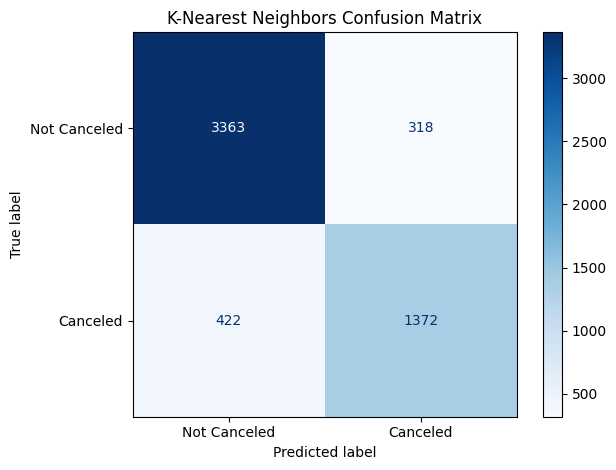

In [ ]:
# Run the model and evaluation
knn_modeling(k=27)
model_evaluation(y_val, y_pred_knn, "K-Nearest Neighbors")

# decision_tree_modeling("entropy", max_depth=10)
# model_evaluation(y_val, y_pred_dt, "Decision Tree")

# logistic_regression_modeling("l2", C=1.0)
# model_evaluation(y_val, y_pred_lr, "Logistic Regression")

# svm_modeling("rbf", C=1.0)
# model_evaluation(y_val, y_pred_svm, "Support Vector Machine")

naive_bayes_modeling()
model_evaluation(y_val, y_pred_nb, "Naive Bayes")

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [ ]:
# Write your code here

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [ ]:
# Write your code here

---

# Saving and Loading Models <a name="9"></a>

---

This section stores the trained models and restores them for prediction.

In [ ]:
def submit(model, X, y, X_test):
    model.fit(X, y)
    predictions = np.array([model.predict(row) for row in X_test], dtype=int)

    result = pd.read_csv(
        CFG.DATA_DIR / "sample_submission.csv",
        dtype={"id": str}
    )

    result["is_canceled"] = predictions

    path = CFG.OUTPUT_DIR / "submission.csv"
    result.to_csv(path, index=False)

    print(f"{len(result)} rows written to {path}")
    display(result.head())

    return result

In [ ]:
final_preparation_pipeline = knn_pipeline()
x_full_prepared = (final_preparation_pipeline.fit_transform(X))
x_test_final_prepared = (final_preparation_pipeline.transform(x_test))

submission = submit(
    KNN(k=27),
    x_full_prepared,
    y,
    x_test_final_prepared
)

6844 rows written to c:\Users\lenovo\Documents\Semester 5\AI\Tubes\IF3170_G12_YuzukiAkatsukiMilikKita\output\submission.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [ ]:
# Write your code here

---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.